In [2]:
import json, glob, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RUNS = "../windevolve_sdwpf/runs"
print("runs dir:", os.path.abspath(RUNS))
found = sorted(os.path.basename(p) for p in glob.glob(RUNS + "/*") if os.path.isdir(p))
print("run folders found:", found)

runs dir: /Users/dorsam/Documents/SRIP 2026/windevolve_sdwpf/runs
run folders found: ['islands1_r1', 'islands1_r2', 'islands1_r3', 'islands3_r1', 'islands3_r2', 'islands3_r3', 'sweep300', 'test002']


In [3]:
def best_info(run_id):
    p = f"{RUNS}/{run_id}/openevolve_output/best/best_program_info.json"
    return json.load(open(p)).get("metrics", {}) if os.path.exists(p) else None

ablation_ids = sorted(os.path.basename(p) for p in glob.glob(RUNS + "/islands*"))
rows = []
for rid in ablation_ids:
    m = best_info(rid)
    if not m:
        continue
    variant = "islands3" if rid.startswith("islands3") else "islands1"
    rows.append({"run": rid, "variant": variant,
                 "farm_score_mw": m.get("farm_score_mw"),
                 "skill": m.get("skill_vs_persistence")})
abl = pd.DataFrame(rows)
dropped = abl[abl["skill"] == 0.0]["run"].tolist()
abl = abl[abl["skill"] != 0.0].reset_index(drop=True)
if dropped:
    print("dropped seed-only (incomplete) runs:", dropped)
print(abl.to_string(index=False))

        run  variant  farm_score_mw    skill
islands1_r1 islands1      34.188859 0.209087
islands1_r2 islands1      36.166370 0.163340
islands1_r3 islands1      35.450404 0.179903
islands3_r1 islands3      35.422742 0.180543
islands3_r2 islands3      34.343526 0.205509
islands3_r3 islands3      35.144582 0.186977


In [4]:
g = abl.groupby("variant")["farm_score_mw"]
summary = g.agg(["count", "mean", "std", "min", "max"])
print(summary.to_string())
m1 = abl[abl.variant == "islands1"].farm_score_mw.mean()
m3 = abl[abl.variant == "islands3"].farm_score_mw.mean()
diff = m1 - m3
spread = abl.groupby("variant").farm_score_mw.std().max()
print()
print(f"mean difference (islands1 - islands3): {diff:+.3f} MW")
print(f"largest within-variant spread:        {spread:.3f} MW")
print("verdict:", "within noise -> NO detectable island effect" if abs(diff) < spread else "difference exceeds noise")

          count       mean       std        min        max
variant                                                   
islands1      3  35.268544  1.001221  34.188859  36.166370
islands3      3  34.970283  0.560323  34.343526  35.422742

mean difference (islands1 - islands3): +0.298 MW
largest within-variant spread:        1.001 MW
verdict: within noise -> NO detectable island effect


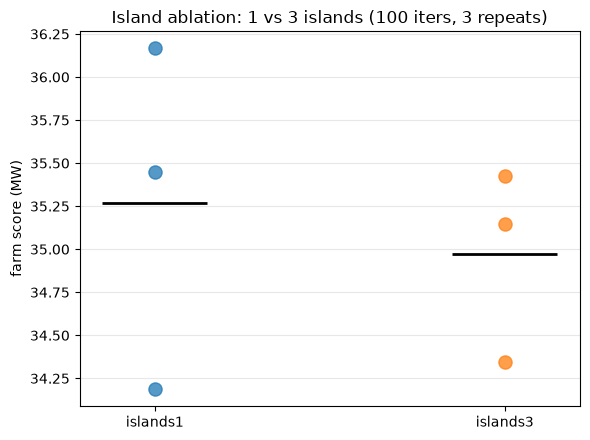

In [15]:
fig, ax = plt.subplots(figsize=(6, 4.5))
variants = ["islands1", "islands3"]
for i, v in enumerate(variants):
    d = abl[abl.variant == v].farm_score_mw.values
    ax.scatter([i] * len(d), d, s=90, alpha=0.75)
    ax.hlines(d.mean(), i - 0.15, i + 0.15, color="black", lw=2)
ax.set_xticks(range(len(variants)))
ax.set_xticklabels(variants)
ax.set_ylabel("farm score (MW)")
ax.set_title("Island ablation: 1 vs 3 islands (100 iters, 3 repeats)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
def curve(run_id):
    base = f"{RUNS}/{run_id}/openevolve_output/checkpoints"
    out = []
    for c in glob.glob(base + "/checkpoint_*"):
        it = int(re.search(r"checkpoint_(\d+)", c).group(1))
        info = os.path.join(c, "best_program_info.json")
        if not os.path.exists(info):
            alt = glob.glob(os.path.join(c, "**", "best_program_info.json"), recursive=True)
            if not alt:
                continue
            info = alt[0]
        mm = json.load(open(info)).get("metrics", {})
        out.append((it, mm.get("farm_score_mw"), mm.get("skill_vs_persistence")))
    return pd.DataFrame(sorted(out), columns=["iter", "farm_score_mw", "skill"])

sweep = curve("sweep300")
print(sweep.to_string(index=False))

 iter  farm_score_mw    skill
    5      40.520734 0.062607
   10      37.534441 0.131691
   15      37.534441 0.131691
   20      37.534441 0.131691
   25      35.382660 0.181470
   30      34.840245 0.194018
   35      34.840245 0.194018
   40      34.840245 0.194018
   45      34.840245 0.194018
   50      34.840245 0.194018
   55      34.821960 0.194441
   60      34.821960 0.194441
   65      34.821960 0.194441
   70      34.821415 0.194454
   75      34.821415 0.194454
   80      34.821415 0.194454
   85      34.821415 0.194454
   90      34.630523 0.198870
   95      34.630523 0.198870
  100      34.630523 0.198870
  105      34.577341 0.200100
  110      34.577341 0.200100
  115      34.577341 0.200100
  120      34.577341 0.200100
  125      34.577341 0.200100
  130      34.577341 0.200100
  135      34.577341 0.200100
  140      34.577341 0.200100
  145      34.549361 0.200747
  150      34.549361 0.200747
  155      34.549361 0.200747
  160      34.549361 0.200747
  165     

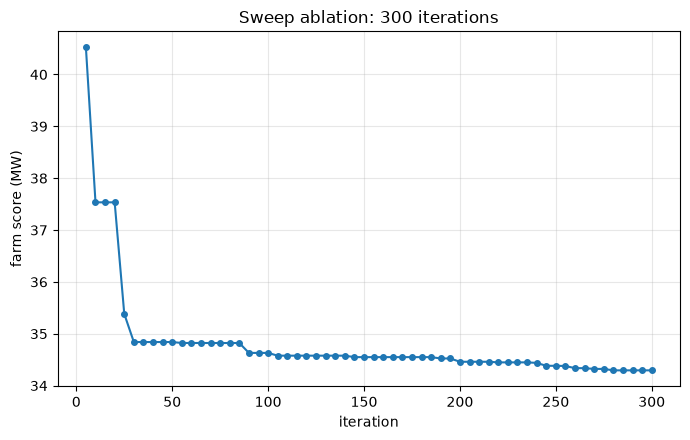

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(sweep["iter"], sweep["farm_score_mw"], marker="o", ms=4)
ax.set_xlabel("iteration")
ax.set_ylabel("farm score (MW)")
ax.set_title("Sweep ablation: 300 iterations")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
first = sweep.iloc[0].farm_score_mw
mid = sweep.iloc[len(sweep) // 2].farm_score_mw
last = sweep.iloc[-1].farm_score_mw
best_overall = min(abl.farm_score_mw.min(), sweep.farm_score_mw.min())
print("=== FINDINGS ===")
print(f"1. Islands (1 vs 3): mean {m1:.2f} vs {m3:.2f} MW, diff {diff:+.2f} < spread {spread:.2f} -> no detectable effect")
print(f"2. Iterations: {first:.1f} -> {mid:.1f} -> {last:.1f} MW")
print(f"   first-half gain {first-mid:+.2f} MW, second-half gain {mid-last:+.2f} MW")
frac = 100 * (first - mid) / (first - last) if (first - last) else float("nan")
print(f"   ~{frac:.0f}% of total improvement in the first half -> converges early, then plateaus")
print(f"3. Best evolved score: {best_overall:.2f} MW  vs persistence ~43, published GRU baseline 42.32")
print(f"   (scale-comparable; official metrics.py verification is a separate step)")

=== FINDINGS ===
1. Islands (1 vs 3): mean 35.27 vs 34.97 MW, diff +0.30 < spread 1.00 -> no detectable effect
2. Iterations: 40.5 -> 34.5 -> 34.3 MW
   first-half gain +5.97 MW, second-half gain +0.26 MW
   ~96% of total improvement in the first half -> converges early, then plateaus
3. Best evolved score: 34.19 MW  vs persistence ~43, published GRU baseline 42.32
   (scale-comparable; official metrics.py verification is a separate step)


In [9]:
from difflib import SequenceMatcher

def evolve_block(code):
    m = re.search(r"EVOLVE-BLOCK-START(.*?)EVOLVE-BLOCK-END", code, re.S)
    return (m.group(1) if m else code).strip()

def load_programs(run_id, checkpoint="checkpoint_300"):
    d = f"{RUNS}/{run_id}/openevolve_output/checkpoints/{checkpoint}/programs"
    progs = []
    for f in glob.glob(os.path.join(d, "*.json")):
        j = json.load(open(f))
        progs.append({"id": j.get("id"),
                      "iter": j.get("iteration_found", j.get("generation", 0)) or 0,
                      "code": evolve_block(j.get("code", "")),
                      "score": (j.get("metrics") or {}).get("combined_score")})
    progs.sort(key=lambda p: p["iter"])
    return progs

progs = load_programs("sweep300")
print(f"programs recovered from checkpoint: {len(progs)}")
print(f"iteration range: {progs[0]['iter']} .. {progs[-1]['iter']}" if progs else "none")

programs recovered from checkpoint: 30
iteration range: 0 .. 300


In [10]:
codes = [p["code"] for p in progs]
n = len(codes)
max_sim_to_earlier = []
for i in range(1, n):
    sims = [SequenceMatcher(None, codes[i], codes[j]).ratio() for j in range(i)]
    max_sim_to_earlier.append(max(sims) if sims else 0.0)
max_sim_to_earlier = np.array(max_sim_to_earlier)

print("PROPOSAL SIMILARITY (evolve-block code, each candidate vs all earlier ones)")
print(f"  mean max-similarity-to-earlier : {max_sim_to_earlier.mean():.3f}")
print(f"  candidates >0.90 similar to an earlier one : {(max_sim_to_earlier>0.90).mean():.1%}")
print(f"  candidates >0.99 (near-duplicate)          : {(max_sim_to_earlier>0.99).mean():.1%}")
scores = [round(p["score"], 4) for p in progs if p["score"] is not None]
if scores:
    print(f"  distinct score levels: {len(set(scores))} of {len(scores)} scored candidates "
          f"({len(set(scores))/len(scores):.1%} unique)")

PROPOSAL SIMILARITY (evolve-block code, each candidate vs all earlier ones)
  mean max-similarity-to-earlier : 0.917
  candidates >0.90 similar to an earlier one : 72.4%
  candidates >0.99 (near-duplicate)          : 34.5%
  distinct score levels: 18 of 30 scored candidates (60.0% unique)


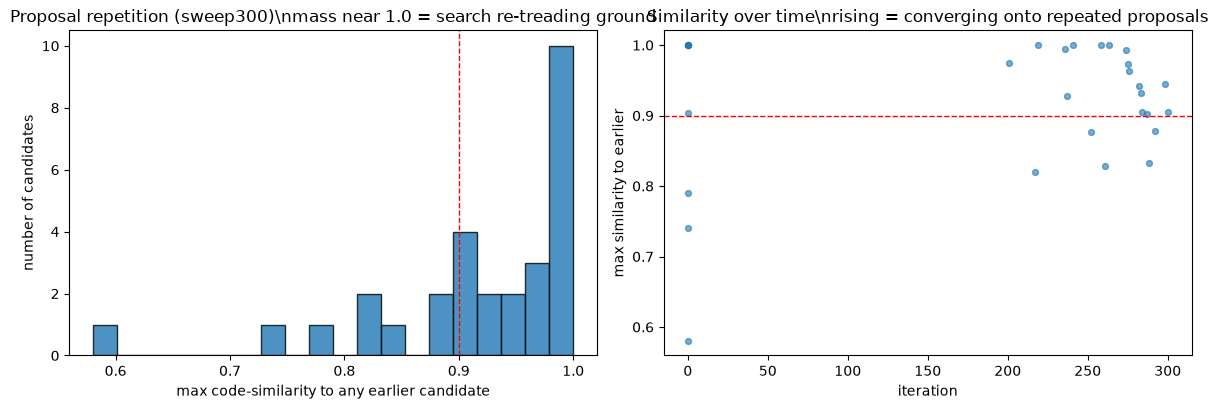

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].hist(max_sim_to_earlier, bins=20, edgecolor="black", alpha=0.8)
ax[0].axvline(0.90, color="red", ls="--", lw=1)
ax[0].set_xlabel("max code-similarity to any earlier candidate")
ax[0].set_ylabel("number of candidates")
ax[0].set_title("Proposal repetition (sweep300)\\nmass near 1.0 = search re-treading ground")
iters = [p["iter"] for p in progs[1:]]
ax[1].scatter(iters, max_sim_to_earlier, s=18, alpha=0.6)
ax[1].axhline(0.90, color="red", ls="--", lw=1)
ax[1].set_xlabel("iteration")
ax[1].set_ylabel("max similarity to earlier")
ax[1].set_title("Similarity over time\\nrising = converging onto repeated proposals")
plt.tight_layout()
plt.show()